**Code**

**Step 1: Import Libraries**

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings("ignore")

**Step 2: Load data and check missing values**

In [19]:
df = pd.read_csv("./diabetes.csv")

print("Dataset Shape:", df.shape)
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


**Step 3: Replace invalid zero values**

In [20]:
cols_with_zeros = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)

print("Missing Values After Replacing Invalid Zeros:")
print(df.isnull().sum())

Missing Values After Replacing Invalid Zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


**Step 4: Exploratory Data Analysis (EDA)**

**Cell 4.1 — Histograms**

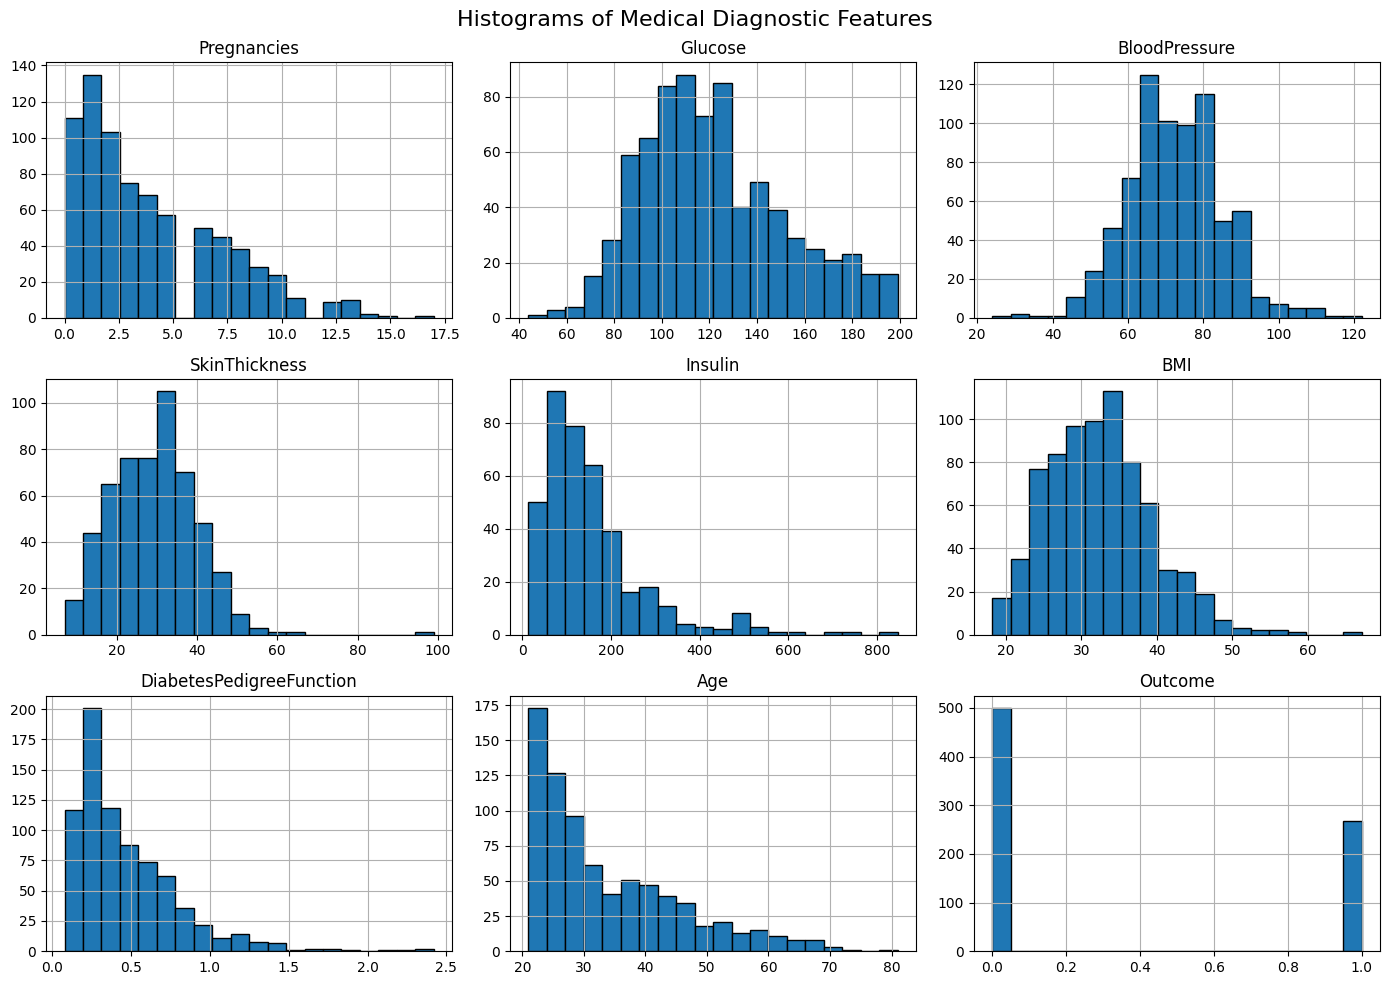

In [21]:
df.hist(bins=20, figsize=(14, 10), edgecolor="black")

plt.suptitle("Histograms of Medical Diagnostic Features", fontsize=16)
plt.tight_layout()
plt.show()

**Cell 4.2 — Correlation heatmap**

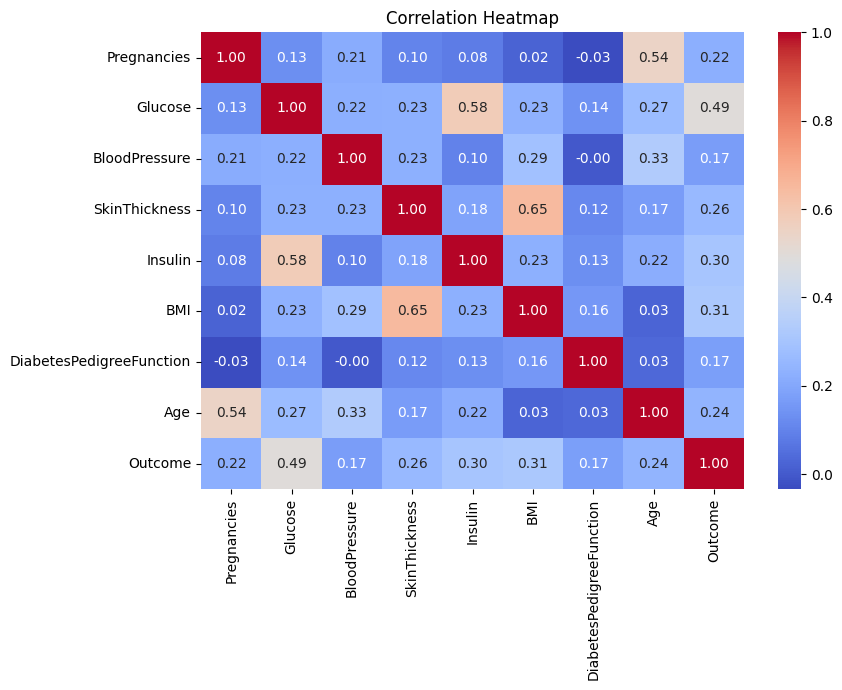

In [22]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

**Cell 4.3 — Diabetes outcome distribution**

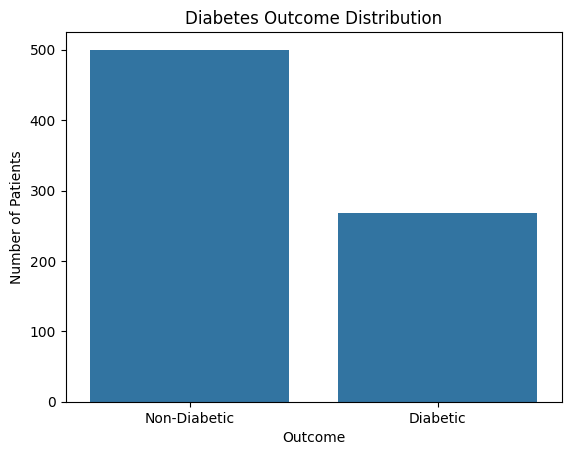

In [23]:
sns.countplot(data=df, x="Outcome")

plt.title("Diabetes Outcome Distribution")
plt.xticks([0, 1], ["Non-Diabetic", "Diabetic"])
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")
plt.show()

**Step 5: Split the dataset**

In [24]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 614
Testing samples: 154


**Step 6: Define the SVM model**

In [25]:
models = {
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC())
    ])
}

**Step 7: Train and evaluate the untuned model**

In [26]:
untuned_results = {}

model = models["SVM"]

model.fit(X_train, y_train)

pred = model.predict(X_test)
acc = accuracy_score(y_test, pred)

untuned_results["SVM"] = {
    "model": model,
    "accuracy": acc,
    "prediction": pred
}

best_untuned_name = "SVM"
best_untuned_model = model
best_untuned_accuracy = acc

print("Untuned SVM Accuracy:", round(acc, 4))

Untuned SVM Accuracy: 0.7403


**Step 8: Define SVM hyperparameters**

In [27]:
param_grids = [
    {
        "model__kernel": ["linear"],
        "model__C": [0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    },
    {
        "model__kernel": ["rbf"],
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", "auto"],
        "model__class_weight": [None, "balanced"]
    }
]

**Step 9: Train and evaluate the tuned SVM**

In [28]:
tuned_results = {}

search = GridSearchCV(
    estimator=models["SVM"],
    param_grid=param_grids,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

search.fit(X_train, y_train)

best_tuned_model = search.best_estimator_

pred = best_tuned_model.predict(X_test)
acc = accuracy_score(y_test, pred)

tuned_results["SVM"] = {
    "model": best_tuned_model,
    "accuracy": acc,
    "prediction": pred
}

best_tuned_name = "SVM"
best_tuned_accuracy = acc

print("Best Parameters:", search.best_params_)
print("Best Cross-Validation F1-score:", round(search.best_score_, 4))
print("Tuned SVM Test Accuracy:", round(acc, 4))

Best Parameters: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best Cross-Validation F1-score: 0.6711
Tuned SVM Test Accuracy: 0.6688


**Step 10: Compare untuned and tuned accuracy**

  Model  Untuned Accuracy  Tuned Accuracy
0   SVM           0.74026        0.668831


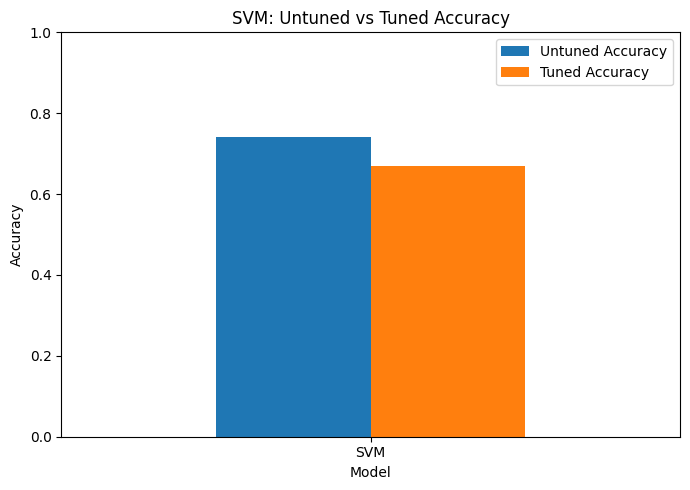

In [29]:
accuracy_df = pd.DataFrame({
    "Model": ["SVM"],
    "Untuned Accuracy": [best_untuned_accuracy],
    "Tuned Accuracy": [best_tuned_accuracy]
})

print(accuracy_df)

accuracy_df.set_index("Model").plot(
    kind="bar",
    figsize=(7, 5),
    ylim=(0, 1)
)

plt.title("SVM: Untuned vs Tuned Accuracy")
plt.ylabel("Accuracy")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Step 11: Confusion matrix and classification report**

UNTUNED SVM


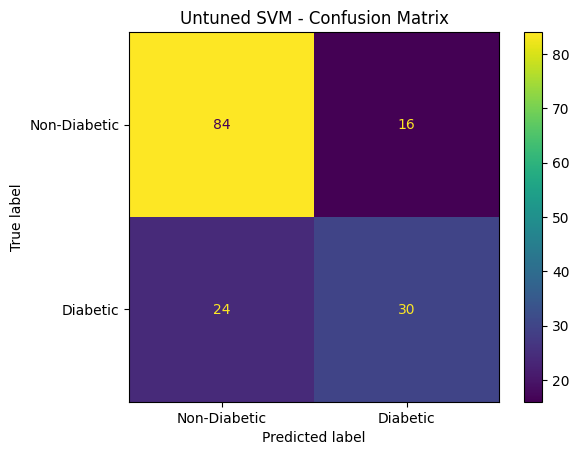

              precision    recall  f1-score   support

Non-Diabetic       0.78      0.84      0.81       100
    Diabetic       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154


TUNED SVM


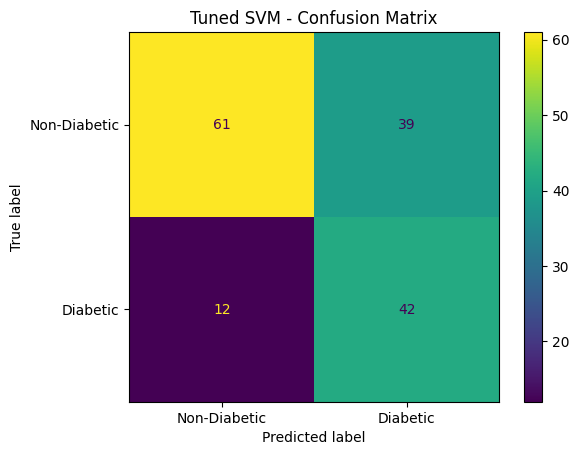

              precision    recall  f1-score   support

Non-Diabetic       0.84      0.61      0.71       100
    Diabetic       0.52      0.78      0.62        54

    accuracy                           0.67       154
   macro avg       0.68      0.69      0.66       154
weighted avg       0.72      0.67      0.68       154



In [30]:
print("UNTUNED SVM")

ConfusionMatrixDisplay.from_estimator(
    best_untuned_model,
    X_test,
    y_test,
    display_labels=["Non-Diabetic", "Diabetic"]
)

plt.title("Untuned SVM - Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    best_untuned_model.predict(X_test),
    target_names=["Non-Diabetic", "Diabetic"],
    zero_division=0
))


print("\nTUNED SVM")

ConfusionMatrixDisplay.from_estimator(
    best_tuned_model,
    X_test,
    y_test,
    display_labels=["Non-Diabetic", "Diabetic"]
)

plt.title("Tuned SVM - Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    best_tuned_model.predict(X_test),
    target_names=["Non-Diabetic", "Diabetic"],
    zero_division=0
))

**Step 12: Feature importance using permutation importance**

                    Feature  Importance
1                   Glucose    0.063659
0               Pregnancies    0.015890
6  DiabetesPedigreeFunction    0.014074
5                       BMI    0.011698
3             SkinThickness    0.008892
7                       Age    0.005607
4                   Insulin    0.000746
2             BloodPressure   -0.011484


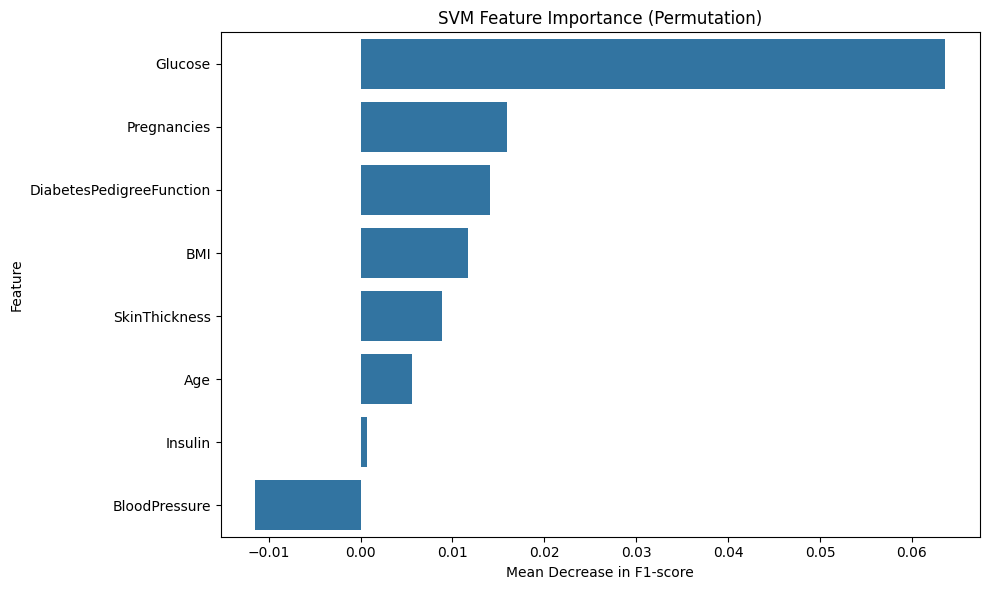

In [31]:
result = permutation_importance(
    best_tuned_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": result.importances_mean
}).sort_values("Importance", ascending=False)

print(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("SVM Feature Importance (Permutation)")
plt.xlabel("Mean Decrease in F1-score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**Step 13: Predict diabetes for test samples**

In [32]:
sample = X_test.iloc[:10]
true_vals = y_test.loc[sample.index]

pred_untuned = best_untuned_model.predict(sample)
pred_tuned = best_tuned_model.predict(sample)

comparison_df = pd.DataFrame({
    "Actual Outcome": true_vals.values,
    "Untuned SVM": pred_untuned,
    "Tuned SVM": pred_tuned
})

comparison_df.replace(
    {0: "Non-Diabetic", 1: "Diabetic"},
    inplace=True
)

print("Test Set Prediction Comparison:")
print(comparison_df)

Test Set Prediction Comparison:
  Actual Outcome   Untuned SVM     Tuned SVM
0   Non-Diabetic      Diabetic      Diabetic
1   Non-Diabetic  Non-Diabetic      Diabetic
2   Non-Diabetic  Non-Diabetic  Non-Diabetic
3       Diabetic  Non-Diabetic  Non-Diabetic
4   Non-Diabetic  Non-Diabetic  Non-Diabetic
5   Non-Diabetic  Non-Diabetic  Non-Diabetic
6       Diabetic  Non-Diabetic      Diabetic
7       Diabetic      Diabetic      Diabetic
8   Non-Diabetic  Non-Diabetic  Non-Diabetic
9   Non-Diabetic      Diabetic      Diabetic
